## GitHub link
https://github.com/camilasoaares/Statistical-Techniques.git

# Data Preparation
- Import library used
- Read the dataset
- Visualise the first and last 5 datas
- Check data size
- Numerical Description Data
- Information about each column if numerical or categorical
- Check missing values

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
data = pd.read_csv('bank-full.csv', sep=';')

In [3]:
data.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


In [4]:
data.tail()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
45206,51,technician,married,tertiary,no,825,no,no,cellular,17,nov,977,3,-1,0,unknown,yes
45207,71,retired,divorced,primary,no,1729,no,no,cellular,17,nov,456,2,-1,0,unknown,yes
45208,72,retired,married,secondary,no,5715,no,no,cellular,17,nov,1127,5,184,3,success,yes
45209,57,blue-collar,married,secondary,no,668,no,no,telephone,17,nov,508,4,-1,0,unknown,no
45210,37,entrepreneur,married,secondary,no,2971,no,no,cellular,17,nov,361,2,188,11,other,no


In [5]:
data.shape

(45211, 17)

In [6]:
data.describe()

,age,balance,day,duration,campaign,pdays,previous
count,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000
mean,40.936210,1362.272058,15.806419,258.163080,2.763841,40.197828,0.580323
std,10.618762,3044.765829,8.322476,257.527812,3.098021,100.128746,2.303441
min,18.000000,-8019.000000,1.000000,0.000000,1.000000,-1.000000,0.000000
25%,33.000000,72.000000,8.000000,103.000000,1.000000,-1.000000,0.000000
50%,39.000000,448.000000,16.000000,180.000000,2.000000,-1.000000,0.000000
75%,48.000000,1428.000000,21.000000,319.000000,3.000000,-1.000000,0.000000
max,95.000000,102127.000000,31.000000,4918.000000,63.000000,871.000000,275.000000


In [7]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   age        45211 non-null  int64 
 1   job        45211 non-null  object
 2   marital    45211 non-null  object
 3   education  45211 non-null  object
 4   default    45211 non-null  object
 5   balance    45211 non-null  int64 
 6   housing    45211 non-null  object
 7   loan       45211 non-null  object
 8   contact    45211 non-null  object
 9   day        45211 non-null  int64 
 10  month      45211 non-null  object
 11  duration   45211 non-null  int64 
 12  campaign   45211 non-null  int64 
 13  pdays      45211 non-null  int64 
 14  previous   45211 non-null  int64 
 15  poutcome   45211 non-null  object
 16  y          45211 non-null  object
dtypes: int64(7), object(10)
memory usage: 5.9+ MB


In [8]:
data.isnull().sum()

age          0
job          0
marital      0
education    0
default      0
balance      0
housing      0
loan         0
contact      0
day          0
month        0
duration     0
campaign     0
pdays        0
previous     0
poutcome     0
y            0
dtype: int64

# Target Variable "y"
## Description and visualisation of the target variable
Plot of value counts for better understanding results of the marketing campaing

In [9]:
data['y'].value_counts()

y
no     39922
yes     5289
Name: count, dtype: int64

In [10]:
data['y'].value_counts(normalize=True)*100

y
no     88.30152
yes    11.69848
Name: proportion, dtype: float64

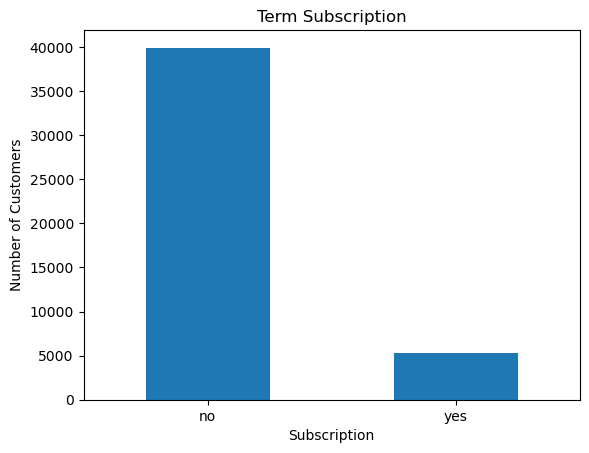

In [11]:
counts = data['y'].value_counts().reindex(['no','yes'])
counts.plot (kind='bar')
plt.title('Term Subscription')
plt.xlabel('Subscription')
plt.ylabel('Number of Customers')
plt.xticks(rotation=0)
plt.show()

# Age Variable 
We selected the variable "age" because it is a quantitative variable that describes the age distribution of customers. 
- Quartiles were used to identify the central spread of the data
- IQR to identify potential outilers
- Graph to visualise and understand the distribution of customer age

In [12]:
age_min=data['age'].min()
age_max=data['age'].max()
print(age_min, age_max)

18 95


In [13]:
range=age_max - age_min
print(range)

77


In [14]:
variance = data['age'].var()
print(variance)

112.75810728286069


In [15]:
standard_dev=data['age'].std()
print(standard_dev)

10.618762040975431


In [16]:
p10=data['age'].quantile(0.10)
p25=data['age'].quantile(0.25)
p50=data['age'].quantile(0.50)
p75=data['age'].quantile(0.75)
print(p10, p25, p50, p75)

29.0 33.0 39.0 48.0


In [17]:
Q3=data['age'].quantile(0.75)
Q1=data['age'].quantile(0.25)
IQR = Q3-Q1
print(IQR)

15.0


In [18]:
lower_bound= Q1 - 1.5 * IQR
upper_bound= Q3 + 1.5 * IQR
outliers=data[(data['age']<lower_bound) | (data['age']> upper_bound)]
print('lower_bound', lower_bound)
print('upper_bound', upper_bound)
print('number of outliers', len(outliers))

lower_bound 10.5
upper_bound 70.5
number of outliers 487


In [19]:
outliers['age']

29158    83
29261    75
29263    75
29322    83
29865    75
         ..
45163    71
45191    75
45204    73
45207    71
45208    72
Name: age, Length: 487, dtype: int64

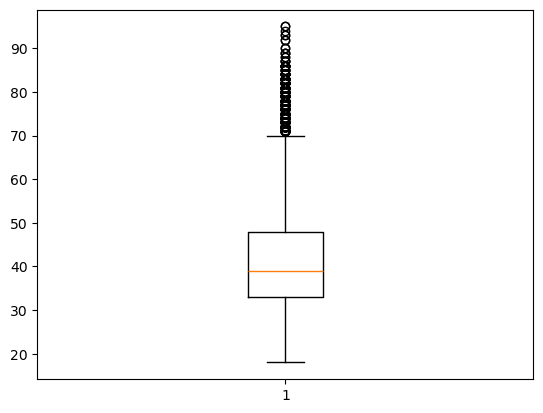

In [20]:
plt.boxplot(data['age'])
plt.show()

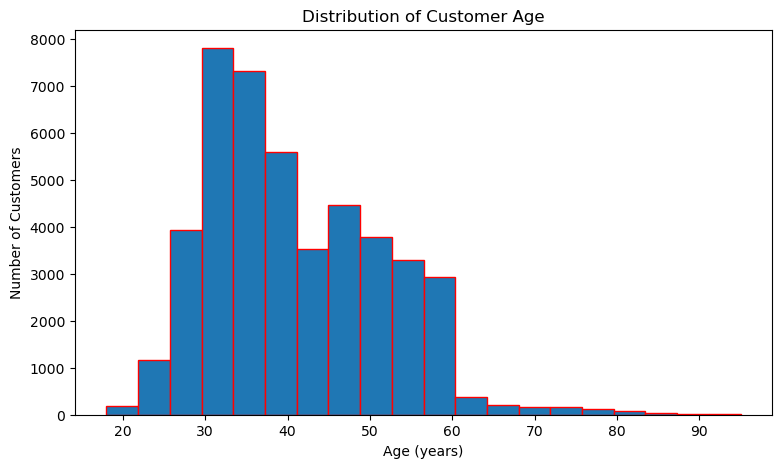

In [41]:
plt.figure(figsize=(9,5))
plt.hist(data['age'], bins=20, edgecolor='red')
plt.title("Distribution of Customer Age")
plt.xlabel("Age (years)")
plt.ylabel('Number of Customers')
plt.show()

# Binomial Distribution
## Variable Y
Binomial distribution is a discrete probability distribution used to estimate the number of success in subscription after the marketing campaing.

To calculate this distribution we used the target variable "y" and the PMF (Probability massa function) because it calculates the probability of a determinate number of success in n numbers of independent trials.

In [22]:
# Count the total number of customers
n_customers = len(data)

# Count the number of customers who subscribed
n_success = (data['y'] == 'yes').sum()

# Calculate the subscription probability
p = n_success / n_customers

print('Total of customers:', n_customers)
print('Successful Subscriptions:', n_success)
print('Estimated probability of subscriptions:', p)
print('Subscriptions percentage:', p*100)

Total of customers: 45211
Successful Subscriptions: 5289
Estimated probability of subscriptions: 0.11698480458295547
Subscriptions percentage: 11.698480458295547


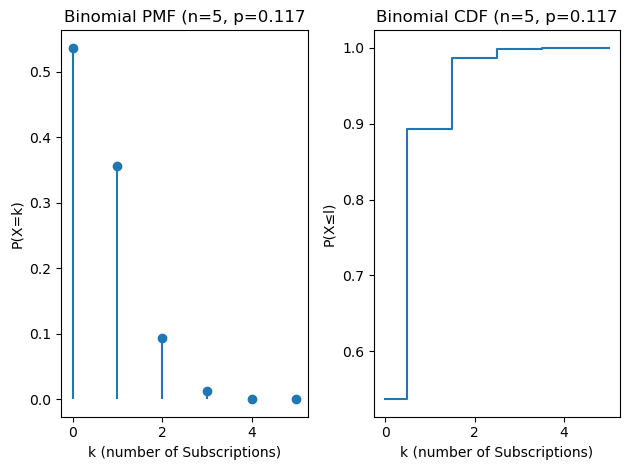

In [42]:
from scipy.stats import binom
# n = number of customers
# p = estimated probability of subscriptions
n, p = 5, 0.11698480458295547

#Possible number of successful subcriptions
x = np.arange(0, n +1)

# PMF and CDF
pmf = binom.pmf(x, n, p)
cdf = binom.cdf(x, n, p)

# PMF PLOT

plt.subplot(1, 2, 1)
plt.stem (x, pmf, basefmt=" ")
plt.title('Binomial PMF (n=5, p=0.117')
plt.xlabel('k (number of Subscriptions)')
plt.ylabel('P(X=k)')

# CDF PLOT
plt.subplot(1,2,2)
plt.step(x, cdf, where="mid")
plt.title('Binomial CDF (n=5, p=0.117')
plt.xlabel('k (number of Subscriptions)')
plt.ylabel('P(X≤l)')

plt.tight_layout()
plt.show()


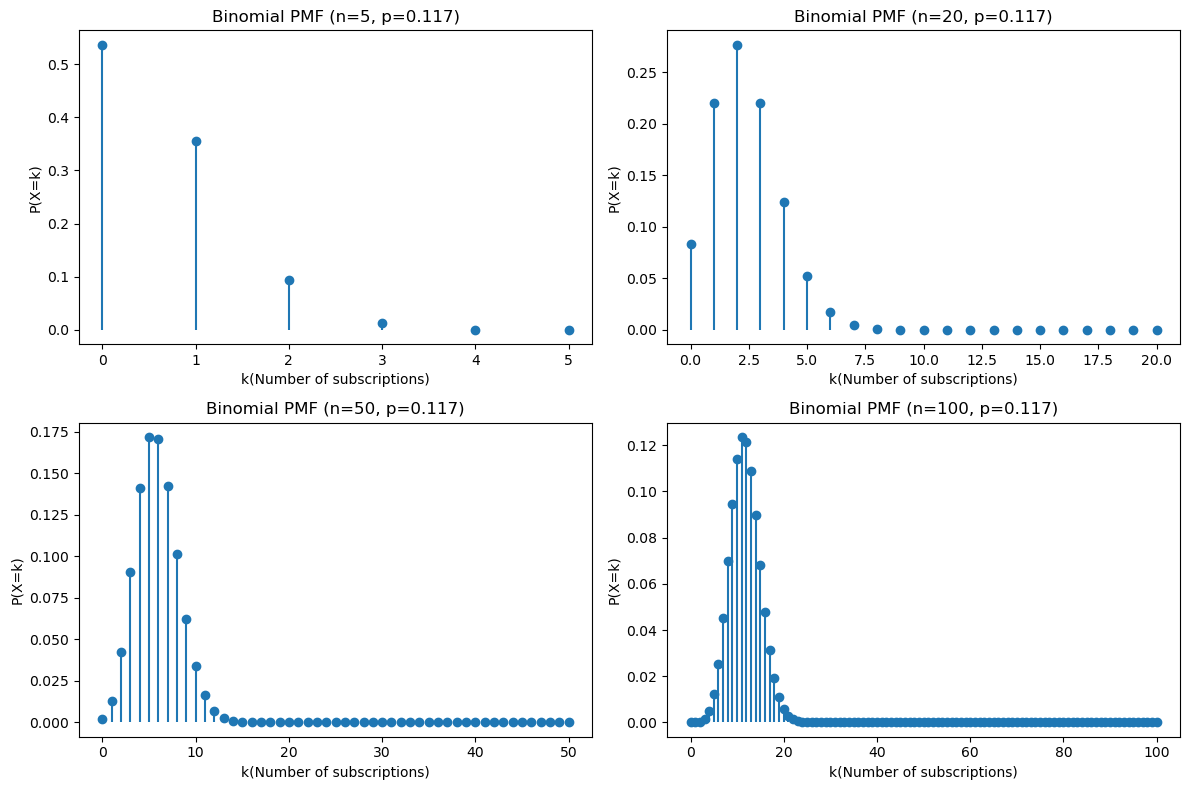

In [43]:
# Estimate subscription probability from the dataset
p = (data['y'] =='yes').mean()

#Different sample sizes
n_values = [5, 20, 50, 100]

#plot PMF for each sample size
plt.figure(figsize=(12, 8))

for i, n in enumerate (n_values, 1):
    x = np.arange(0, n+1)
    pmf = binom.pmf(x,n,p)
    plt.subplot (2, 2, i)
    plt.stem(x, pmf, basefmt=" ")
    plt. title(f'Binomial PMF (n={n}, p={p:.3f})')
    plt.xlabel('k(Number of subscriptions)')
    plt.ylabel('P(X=k)')

plt.tight_layout()
plt.show()

In [25]:
# Theoretical mean and variance
for n in n_values:
    mean = n*p
    variance = n * p * (1 - p)
    print (f'n = {n}')
    print (f'Expected number of subscriptions: {mean:.2f}')
    print (f'Variance: {variance:.2f}')
    print()

n = 5
Expected number of subscriptions: 0.58
Variance: 0.52

n = 20
Expected number of subscriptions: 2.34
Variance: 2.07

n = 50
Expected number of subscriptions: 5.85
Variance: 5.16

n = 100
Expected number of subscriptions: 11.70
Variance: 10.33



# Poisson 
## Variable: campaing 
It represents the number of marketing contacts during this campaign that was made for each client

The Poisson distribution deals with the number of random occurrences over a period of time or a given space (RMIT University). In this case we can investigage if this vairable describe the frequency of contacts per client.

The variable "campaign" represents the number of contacts made during the marketing campaing for each customer. We also used PMF because we can compare the theorical probability with the frequency in our dataset

In [26]:
# Calculate the mean and variance of campaing
campaign_mean = data['campaign'].mean()
campaign_variance = data['campaign'].var()
print('Mean number of contacts:', campaign_mean)
print('Variance of contacts:', campaign_variance)

Mean number of contacts: 2.763840658246887
Variance of contacts: 9.597733393240357


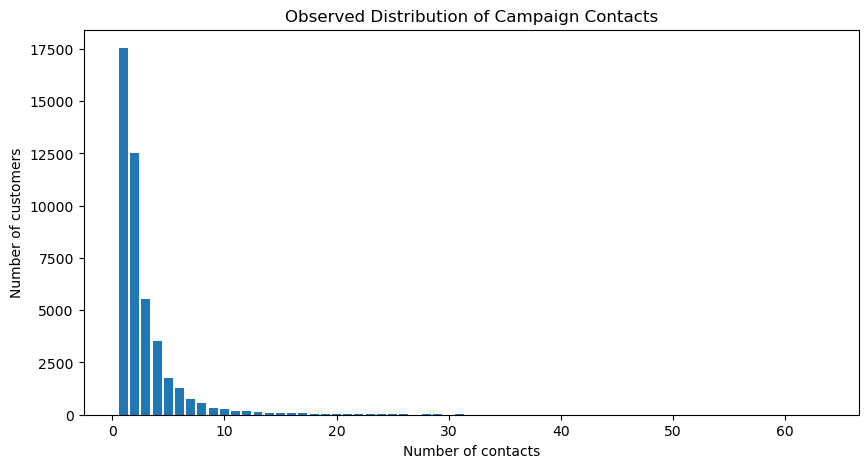

In [27]:
#Visualise the distribution

campaign_counts = data['campaign'].value_counts().sort_index()
plt.figure(figsize=(10,5))
plt.bar(campaign_counts.index, campaign_counts.values)
plt.title('Observed Distribution of Campaign Contacts')
plt.xlabel('Number of contacts')
plt.ylabel('Number of customers')
plt.show()

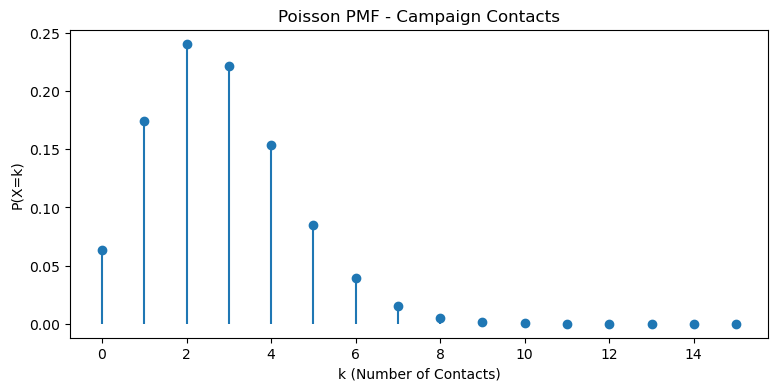

In [28]:
from scipy.stats import poisson

# Parameter
lambda_value = campaign_mean

#possible numbers of contacts
x = np.arange(0,16)

# Probability Mass Funtions
poisson_pmf = poisson.pmf(x, lambda_value)

#Plot PMF
plt.figure(figsize=(9,4))
plt.stem(x, poisson_pmf, basefmt=" ")
plt.title('Poisson PMF - Campaign Contacts')
plt.xlabel('k (Number of Contacts)')
plt.ylabel('P(X=k)')
plt.show()


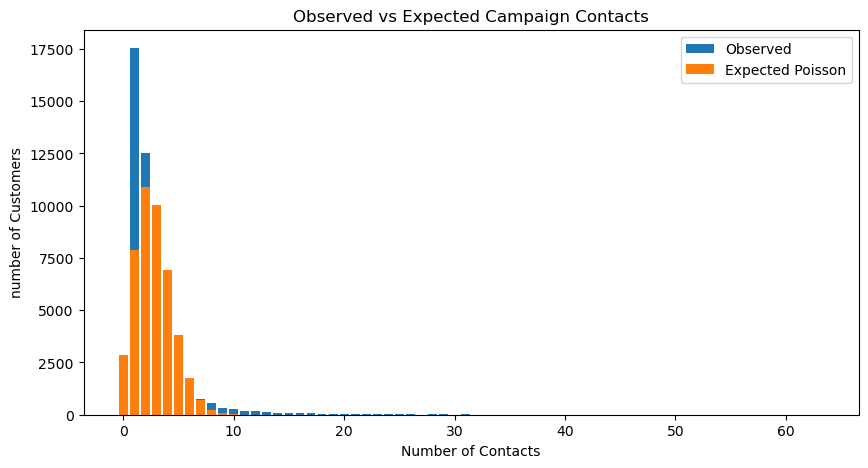

In [29]:
#Expected frequencies under the Poisson model
expected_counts = poisson_pmf * len(data)

#Compare observed and expected frequencies
plt.figure(figsize=(10,5))
plt.bar(
    campaign_counts.index,
    campaign_counts.values,
    label="Observed"
)

plt.bar(
    x,
    expected_counts,
    label="Expected Poisson"
)
plt.title('Observed vs Expected Campaign Contacts')
plt.xlabel('Number of Contacts')
plt.ylabel("number of Customers")
plt.legend()
plt.show()

# Normal Distribution
Variable used: Age

As showed previously, age distribution is assimetric, this allow us investigate if a normal distribution represents well if real datas.

In [30]:
age_mean = data['age'].mean()
# We already calculated the std 
print('Mean Age', age_mean)
print('Standard deviation of age:', standard_dev)

Mean Age 40.93621021432837
Standard deviation of age: 10.618762040975431


# 68 - 95 - 99,7 Emperical Rule

In [31]:
within1 = ((data['age'] >= age_mean - standard_dev) & (data['age'] <= age_mean + standard_dev)).mean() *100
within2 = ((data['age'] >= age_mean - 2*standard_dev) & (data['age'] <= age_mean + 2* standard_dev)).mean() *100
within3 = ((data['age'] >= age_mean - 3*standard_dev) & (data['age'] <= age_mean + 3*standard_dev)).mean() *100
print(within1, within2, within3)

66.0502974939727 97.77045409303045 99.15728473159187


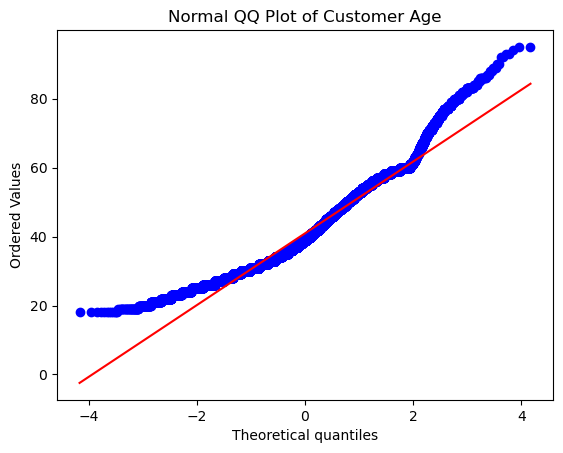

In [32]:
# check normal distribution using QQ plot
from scipy import stats
stats.probplot(data['age'], dist='norm', plot=plt)
plt.title("Normal QQ Plot of Customer Age")
plt.show()

# Central Limit Theorem

In [33]:
# Create a dataset's copy
CLTDATA = data.copy()
CLTDATA.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


In [34]:
#Create the population using customer age
marketing = CLTDATA['age'].dropna()
marketing.shape

(45211,)

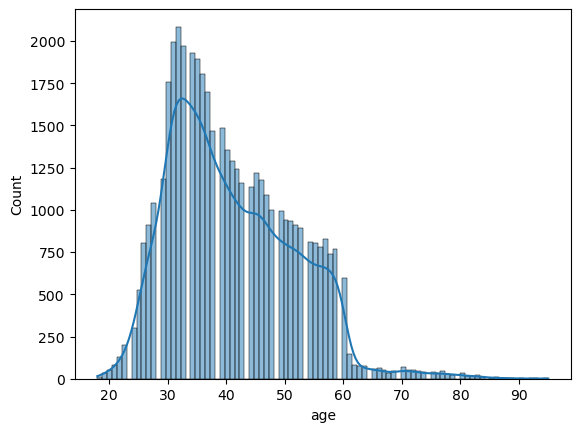

In [35]:
sns.histplot(marketing, kde=True)
plt.show()

In [36]:
print(range)

77


In [37]:
del range

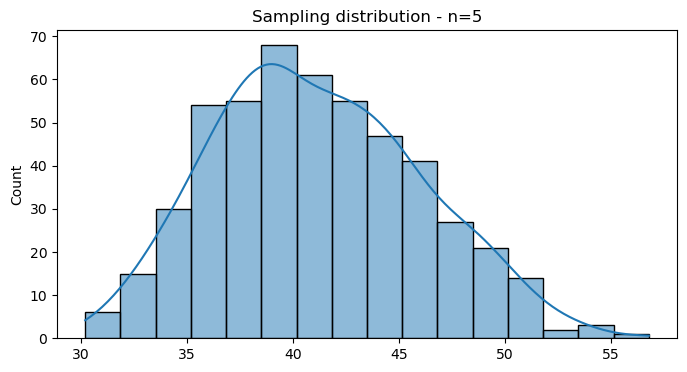

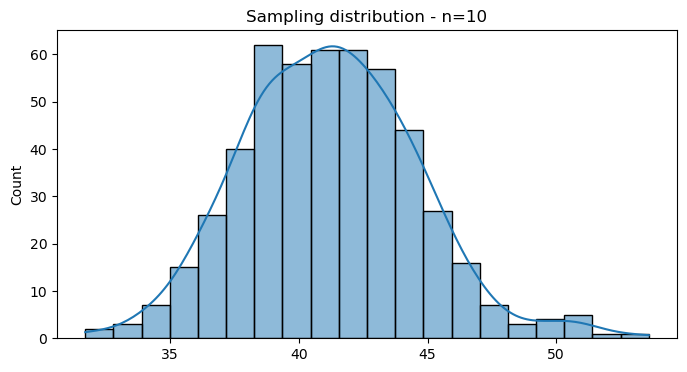

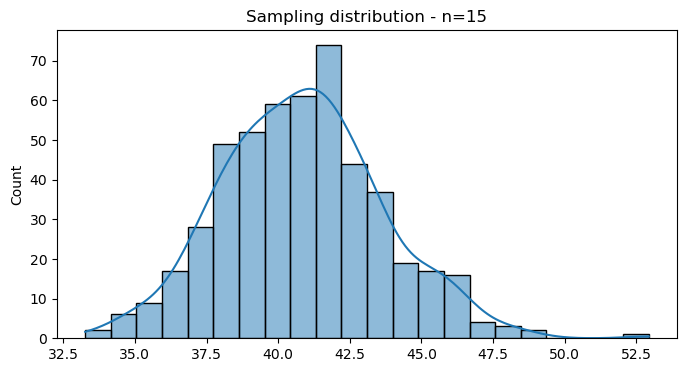

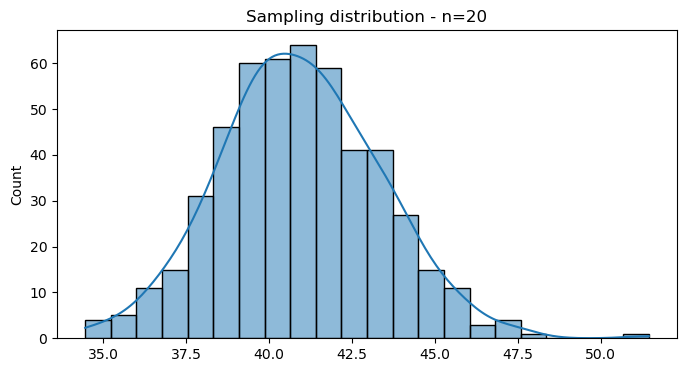

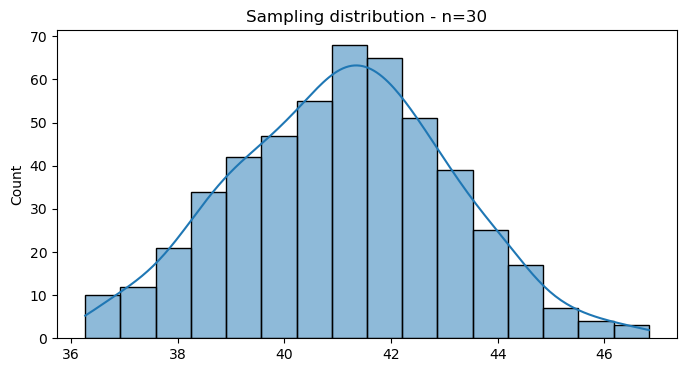

In [40]:
# Testing samples
sample_size = [5, 10, 15, 20, 30]

for size in sample_size:
    means = []

    for i in range(500):
        sample = marketing.sample(n=size, replace=True)
        mean = sample.mean()
        means.append(mean)

    plt.figure(figsize=(8, 4))
    sns.histplot(means, kde=True)

    dist_mean = sum(means) / len(means)

    plt.title(f"Sampling distribution - n={size}")
    plt.show()